# 💳 Financial Complaint & Response Analysis
*Financial Services Analytics | Binary Classification*

> Which financial products receive the most reported complaints, and can complaint details help predict whether a case will close with relief?

## Introduction

A financial-services team wants to understand the most common consumer complaints and how companies classify their responses. As data scientists, our goal is to explore complaint patterns and test whether structured complaint information can help **estimate recorded closure outcomes**.

We use a manageable extract from the public **Consumer Financial Protection Bureau (CFPB)** complaint database and build an interpretable binary classifier.

**Dataset source:** [CFPB Consumer Complaint Database](https://www.consumerfinance.gov/data-research/consumer-complaints/)  
**Problem Type:** Descriptive Analytics | Supervised Learning | Binary Classification  
**Methods:** Exploratory Data Analysis · Logistic Regression · Stratified Random Train/Test Split

> **Important:** Published complaints are not a representative sample of all customers. A company's response category is not a measure of customer satisfaction or proof that a complaint was resolved correctly. Complaint narratives are not used.

## Business Problem | What Does the Financial Services Team Want to Know?

- **Which financial products receive the most complaints?** → Identify areas for closer review.
- **What issues are reported most often?** → Highlight potential process and service problems.
- **How do companies record their responses?** → Examine closure categories and the share with reported relief.
- **Which products have higher reported relief shares?** → Compare outcomes across product groups, not complaint rates.
- **Can we predict recorded relief categories?** → Compare a Logistic Regression model with a simple baseline.

**Business objective:** Generate insights for investigation and workload planning, **not automated decisions about consumers**

## Dataset Overview & Data Dictionary

Each row represents one published consumer complaint. We use up to **20,000 records** to keep the notebook practical and easy to run.

| Column | Description |
|---|---|
| `Complaint ID` | Unique complaint identifier, if available |
| `Date received` | Date the CFPB received the complaint |
| `Product` | Financial product category |
| `Issue` | Consumer-reported complaint issue |
| `Company` | Company named in the complaint |
| `State` | Reported U.S. state |
| `Submitted via` | Submission channel |
| `Company response to consumer` | Company's reported response category |

**Target Variable:** `relief` (0 or 1) — Indicates whether a complaint was closed with reported relief. The target definition is explained in the **Define the Classification Target** section.

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## Load Data

**Data Loading Method: Local CSV or CFPB API**

This project demonstrates two ways to load data using Pandas:

- **Local CSV:** The notebook first checks whether `complaints.csv` is available in the working directory
- **CFPB API:** If the local file is missing, the notebook retrieves a filtered CSV dataset for January 2024 directly from the official CFPB API

Both methods are limited to **20,000 rows** to keep the analysis manageable

**Note:** This is API-based data retrieval, not traditional web scraping. The first 20,000 records are not a random or representative sample. Results may differ depending on the data source used

In [2]:
file = Path('complaints.csv')
url = ('https://www.consumerfinance.gov/data-research/consumer-complaints/search/api/v1/'
       '?date_received_min=2024-01-01&date_received_max=2024-01-31'
       '&field=all&format=csv&no_aggs=true&size=20000&sort=created_date_desc')
columns = {'complaint id', 'date received', 'product', 'issue', 'company',
           'state', 'submitted via', 'company response to consumer'}
source = file if file.exists() else url

df = pd.read_csv(source, nrows=20000,
                 usecols=lambda c: c.strip().lower() in columns, low_memory=False)
print('Data source:', 'Local CSV' if file.exists() else 'CFPB filtered export')
print('Rows, columns:', df.shape)
display(df.head())

Data source: Local CSV
Rows, columns: (20000, 8)


,Date received,Product,Issue,Company,State,Submitted via,Company response to consumer,Complaint ID
0,2024-01-19,Debt collection,False statements or representation,FIRST AMERICAN FINANCIAL CORPORATION,CA,Web,Closed with explanation,8182721
1,2024-07-24,Credit reporting or other personal consumer re...,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",IL,Phone,Closed with non-monetary relief,9604813
2,2024-10-21,Vehicle loan or lease,Managing the loan or lease,WELLS FARGO & COMPANY,NJ,Web,Closed with explanation,10523066
3,2024-11-01,Vehicle loan or lease,Managing the loan or lease,WELLS FARGO & COMPANY,NJ,Web,Closed with explanation,10657995
4,2025-05-02,Credit card,Fees or interest,WELLS FARGO & COMPANY,NJ,Web,Closed with explanation,13300649


## Data Quality & Preparation

Before analysis, let's check missing values, duplicate complaint IDs and the date range. We remove rows without a usable date, product or recorded response, and keep **closed cases only** when defining the model target

In [3]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(' ', '_', regex=False).str.replace('?', '', regex=False))
required = ['date_received', 'product', 'issue', 'company', 'state',
            'submitted_via', 'company_response_to_consumer']
missing = [c for c in required if c not in df]
if missing:
    raise ValueError(f'Missing columns: {missing}. Check your CFPB CSV export.')

df['date_received'] = pd.to_datetime(df['date_received'], errors='coerce')
print('Missing values:\n', df.isna().sum().sort_values(ascending=False).head(8))
if 'complaint_id' in df:
    print('Duplicate complaint IDs:', df['complaint_id'].duplicated().sum())
    df = df.drop_duplicates('complaint_id')

df = df.dropna(subset=['date_received', 'product', 'company_response_to_consumer']).copy()
print('Usable records:', len(df))
print('Date range:', df['date_received'].min().date(), 'to', df['date_received'].max().date())

Missing values:
 state                           19
date_received                    0
issue                            0
product                          0
company                          0
submitted_via                    0
company_response_to_consumer     0
complaint_id                     0
dtype: int64
Duplicate complaint IDs: 0
Usable records: 20000
Date range: 2024-01-19 to 2026-09-17


## Exploratory Data Analysis (EDA)

### Most Reported Financial Products

Which financial products appear most frequently in our extract? These are **complaint counts**, not complaint rates per customer

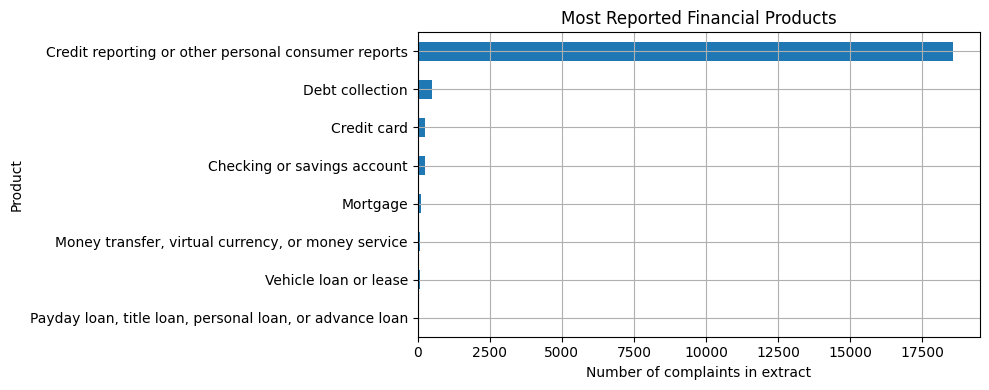

In [4]:
product_counts = df['product'].value_counts()
product_counts.head(8).sort_values().plot.barh(title='Most Reported Financial Products')
plt.xlabel('Number of complaints in extract')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

### Common Complaint Issues

Frequent issues can help teams decide where to investigate service processes and provide additional support

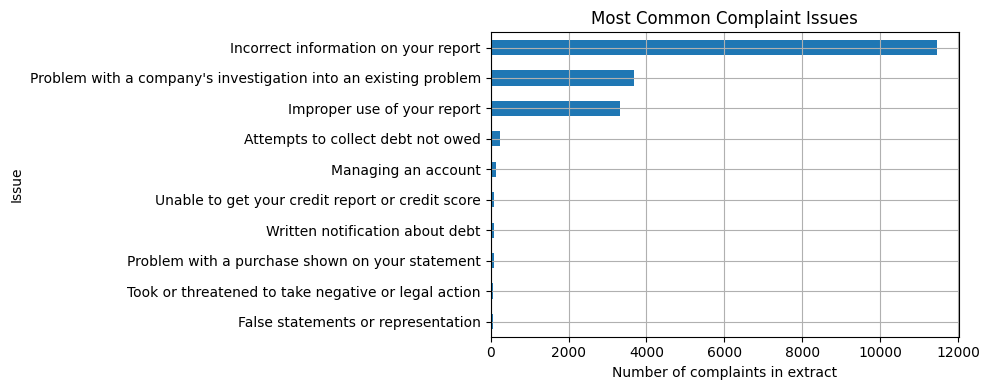

In [5]:
issues = df['issue'].fillna('Unknown').value_counts()
issues.head(10).sort_values().plot.barh(title='Most Common Complaint Issues')
plt.xlabel('Number of complaints in extract')
plt.ylabel('Issue')
plt.tight_layout()
plt.show()

### Company Response Categories

Let's examine recorded response categories before defining our target. These categories do **not** directly measure satisfaction

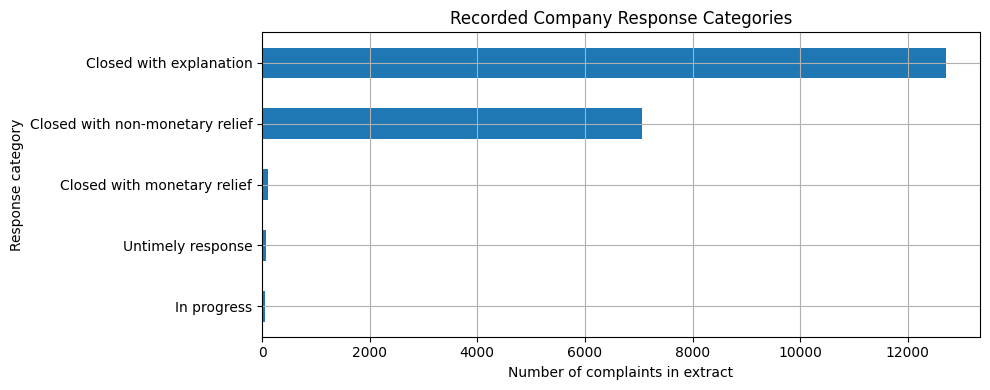

In [6]:
response_counts = df['company_response_to_consumer'].value_counts()
response_counts.head(8).sort_values().plot.barh(title='Recorded Company Response Categories')
plt.xlabel('Number of complaints in extract')
plt.ylabel('Response category')
plt.tight_layout()
plt.show()

## Define the Classification Target

We analyze complaints with a response starting with **Closed**. Positive outcomes are identified using **exact category labels**, not a general text search for the word “relief”:

- `Closed with monetary relief`
- `Closed with non-monetary relief`
- `Closed with relief` (historical label, if present)

All other closed categories—including `Closed without relief`—are assigned `0`. This target describes a **company-reported outcome**, not whether the consumer was satisfied.

In [7]:
cases = df[df['company_response_to_consumer'].str.startswith('Closed', na=False)].copy()
relief_labels = {'Closed with monetary relief', 'Closed with non-monetary relief', 'Closed with relief'}
cases['relief'] = cases['company_response_to_consumer'].isin(relief_labels).astype(int)

print('Closed cases:', len(cases))
print('Recorded relief share:', round(cases['relief'].mean() * 100, 1), '%')
print('Class counts:\n', cases['relief'].value_counts())

Closed cases: 19882
Recorded relief share: 36.1 %
Class counts:
 relief
0    12705
1     7177
Name: count, dtype: int64


### Recorded Relief Share by Product

Comparing proportions helps us explore differences between products with different complaint volumes. We only show product categories with **at least 50 closed complaints** in this extract

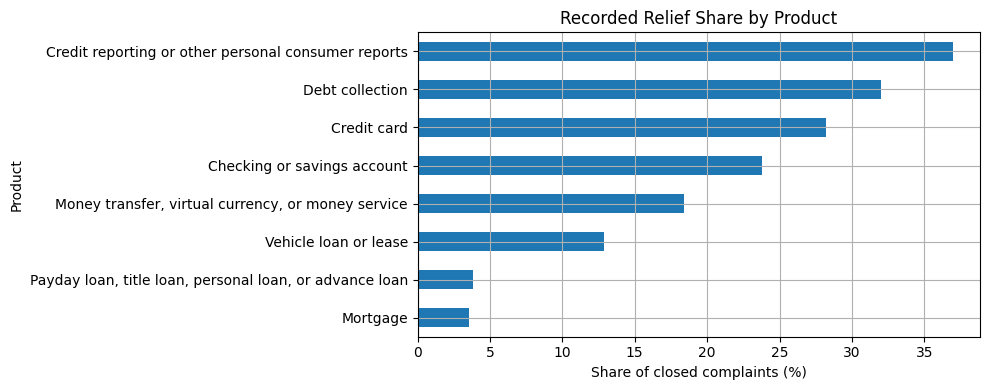

In [8]:
product_relief = cases.groupby('product')['relief'].agg(['mean', 'size'])
product_relief = product_relief[product_relief['size'] >= 50].sort_values('size', ascending=False).head(8)
(product_relief['mean'] * 100).sort_values().plot.barh(title='Recorded Relief Share by Product')
plt.xlabel('Share of closed complaints (%)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

## Build the Classification Model

We use **One-Hot Encoding and Logistic Regression** to predict whether a complaint will close with recorded relief.

The dataset is randomly divided into **80% training data and 20% test data** using `train_test_split()`.

The model learns from the training data, while the test data is used to evaluate its performance.

We use **Accuracy, Precision, Recall, F1-Score and a Confusion Matrix** to evaluate the model.

In [9]:
from sklearn.model_selection import train_test_split

features = ['product', 'issue', 'company', 'state', 'submitted_via']

X = cases[features].fillna('Unknown')
y = cases['relief']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = Pipeline([
    ('encode', ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), features)
    ])),
    ('classify', LogisticRegression(max_iter=400, class_weight='balanced'))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print('Training:', len(X_train), '| Test:', len(X_test))
print(classification_report(y_test, pred, zero_division=0))

Training: 15905 | Test: 3977
              precision    recall  f1-score   support

           0       0.78      0.46      0.58      2541
           1       0.45      0.77      0.57      1436

    accuracy                           0.57      3977
   macro avg       0.61      0.62      0.57      3977
weighted avg       0.66      0.57      0.58      3977



## Model Evaluation

A good evaluation needs a **baseline**. Here, we compare Logistic Regression with predicting the most common training label for every test case.

- **Macro F1** gives equal importance to both classes
- **Accuracy** shows the overall proportion of correct labels
- **Confusion Matrix** makes incorrect predictions visible

A higher Macro F1 does not automatically mean the model is better for every business use case

Macro F1 – Model: 0.575 | Baseline: 0.390
Accuracy – Model: 0.575 | Baseline: 0.639


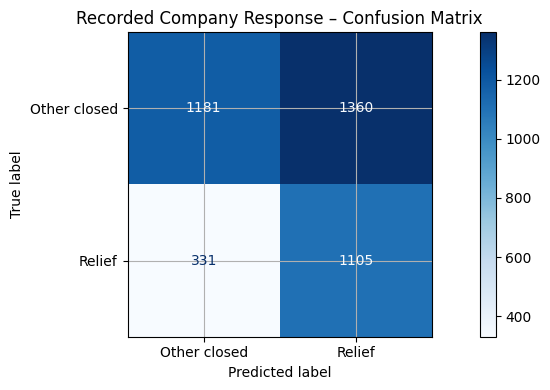

In [10]:
base_pred = np.repeat(y_train.mode()[0], len(y_test))
model_f1 = f1_score(y_test, pred, average='macro', zero_division=0)
base_f1 = f1_score(y_test, base_pred, average='macro', zero_division=0)
model_acc = accuracy_score(y_test, pred)
base_acc = accuracy_score(y_test, base_pred)

print(f'Macro F1 – Model: {model_f1:.3f} | Baseline: {base_f1:.3f}')
print(f'Accuracy – Model: {model_acc:.3f} | Baseline: {base_acc:.3f}')
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
    display_labels=['Other closed', 'Relief'], cmap='Blues')
plt.title('Recorded Company Response – Confusion Matrix')
plt.tight_layout()
plt.show()

## Business Insights & Recommendations

What can a financial-services team do with these results?

- **Investigate frequent issues:** Review high-volume complaint categories and their underlying processes
- **Compare response categories carefully:** Reported relief shares can inform questions for follow-up, but are **not company performance rankings**
- **Use the model as a diagnostic experiment:** Compare Macro F1 and Accuracy with the baseline before deciding whether the classifier adds value
- **Validate before deployment:** Use additional time periods and customer/exposure data; review subgroup stability and potential bias

**Important:** No automated consumer decision should be based on these predictions

## Conclusion

This project combines **Exploratory Data Analysis (EDA)** and **Binary Classification** to analyze publicly reported financial complaints. We identified common complaint products and issues, examined recorded company responses, and trained a Logistic Regression classifier to predict recorded closure outcomes.

**Model Results (80% training / 20% test, stratified random split):**

- **Macro F1:** 0.575 (Baseline: 0.390)
- **Accuracy:** 57.5% (Baseline: 63.9%)
- **Relief class:** Precision 45% · Recall 77%

The model achieves a higher **Macro F1** than the majority-class baseline, but lower **Accuracy**. Its higher recall for the relief class comes with many false-positive predictions. The results are exploratory and do not demonstrate reliable performance on future complaints.

**Key Takeaway:** Complaint data can support process reviews and model experimentation, but recorded company responses are **not** a measure of customer satisfaction. The findings should not be used for automated consumer decisions.

**Next Steps:** Evaluate on a later time period, examine model errors and subgroup stability, and test whether additional reliable data improves prediction quality.


**Source:** [Consumer Financial Protection Bureau – Consumer Complaint Database](https://www.consumerfinance.gov/data-research/consumer-complaints/)
